# Lorenz 96 multi-échelle — bac à sable

Système de Thornes et al. (2017), tel que codé par Chattopadhyay et al. (`Lorenznormalized.m`) :

$$\frac{dX_k}{dt} = X_{k-1}(X_{k+1}-X_{k-2}) - X_k + F - \frac{hc}{b}\sum_j Y_{j,k}$$
$$\frac{dY_{j,k}}{dt} = -cb\,Y_{j+1,k}(Y_{j+2,k}-Y_{j-1,k}) - c\,Y_{j,k} + \frac{hc}{b}X_k - \frac{he}{d}\sum_i Z_{i,j,k}$$
$$\frac{dZ_{i,j,k}}{dt} = ed\,Z_{i-1,j,k}(Z_{i+1,j,k}-Z_{i-2,j,k}) - g\,e\,Z_{i,j,k} + \frac{he}{d}Y_{j,k}$$

Chaque $X_k$ a ses $J$ variables $Y$, chaque $Y_{j,k}$ a ses $I$ variables $Z$ (périodicité par secteur).
On modifie les paramètres dans la cellule suivante, puis on relance tout (*Run All*).


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ============================== PARAMETRES A MODIFIER ==============================
USE_Y = True        # False -> X seul = Lorenz 96 classique (le terme de couplage disparait)
USE_Z = True        # False -> X + Y seulement (2 niveaux). Ignore si USE_Y = False.

K, J, I = 8, 8, 8   # nb de X ; nb de Y par X ; nb de Z par Y

F = 20.0            # forcage de X
h = 1.0             # force de TOUS les couplages (0 = niveaux decouples)
b, c = 10.0, 10.0   # Y : c = rapport d'echelle de temps X/Y (c grand -> Y rapide),
                    #     b = rapport d'amplitude X/Y
d, e = 10.0, 10.0   # Z : meme role que b, c mais entre Y et Z
g = 1.0             # amortissement de Z. Code des auteurs : 1. Article imprime : 10.

dt       = 0.005    # pas RK4 (ne pas augmenter si c ou e sont grands)
N_LT     = 15       # duree tracee en temps de Lyapunov
LAMBDA   = 4.5      # exposant de Lyapunov utilise pour convertir LT -> temps (papier : 4.5/MTU)
SPIN_UP  = 20.0     # duree ignoree au debut (en MTU), pour quitter le transitoire
SEED     = 0


In [2]:
def rhs(X, Y, Z):
    """Derivees. X:(K,)  Y:(J,K) ou None  Z:(J,K,I) ou None."""
    dX = np.roll(X, 1)*(np.roll(X, -1) - np.roll(X, 2)) - X + F
    dY = dZ = None
    if Y is not None:
        dX = dX - h*c/b * Y.sum(0)
        dY = (-c*b*np.roll(Y, -1, 0)*(np.roll(Y, -2, 0) - np.roll(Y, 1, 0))
              - c*Y + h*c/b * X[None, :])
        if Z is not None:
            dY = dY - h*e/d * Z.sum(2)
            dZ = (e*d*np.roll(Z, 1, 2)*(np.roll(Z, -1, 2) - np.roll(Z, 2, 2))
                  - g*e*Z + h*e/d * Y[:, :, None])
    return dX, dY, dZ


def add(S, dS, a):
    return tuple(None if s is None else s + a*ds for s, ds in zip(S, dS))


def rk4(S):
    k1 = rhs(*S); k2 = rhs(*add(S, k1, dt/2)); k3 = rhs(*add(S, k2, dt/2)); k4 = rhs(*add(S, k3, dt))
    return tuple(None if s is None else s + dt/6*(a + 2*b_ + 2*c_ + d_)
                 for s, a, b_, c_, d_ in zip(S, k1, k2, k3, k4))


In [3]:
# ------------------------------ dimensions ------------------------------
use_Z = USE_Y and USE_Z
nX, nY, nZ = K, (K*J if USE_Y else 0), (K*J*I if use_Z else 0)
print("=== DIMENSIONS ===")
print(f"X : K = {K} variables")
print(f"Y : " + (f"J x K = {J} x {K} = {nY} variables  ({J} par X)" if USE_Y else "desactive"))
print(f"Z : " + (f"I x J x K = {I} x {J} x {K} = {nZ} variables  ({I} par Y)" if use_Z else "desactive"))
print(f"total : {nX + nY + nZ} variables  ->  "
      + ("Lorenz 96 classique" if not USE_Y else "2 niveaux (X,Y)" if not use_Z else "3 niveaux (X,Y,Z)"))

# ------------------------------ simulation ------------------------------
rng = np.random.default_rng(SEED)
S = (rng.integers(-5, 6, K).astype(float),
     rng.standard_normal((J, K)) if USE_Y else None,
     0.05*rng.standard_normal((J, K, I)) if use_Z else None)

for _ in range(int(SPIN_UP/dt)):
    S = rk4(S)

T_total = N_LT / LAMBDA
n_steps = int(round(T_total/dt))
t  = np.arange(n_steps)*dt
Xs = np.empty((n_steps, K))
Ys = np.empty((n_steps, J, K)) if USE_Y else None
Zs = np.empty((n_steps, J, K, I)) if use_Z else None
for n in range(n_steps):
    S = rk4(S)
    Xs[n] = S[0]
    if USE_Y: Ys[n] = S[1]
    if use_Z: Zs[n] = S[2]
    if not np.isfinite(S[0]).all():
        raise FloatingPointError(f"divergence au pas {n} : baisse dt")

print(f"\n=== TEMPS ===\n{N_LT} LT = {T_total:.2f} MTU = {n_steps} pas de dt = {dt}  "
      f"(1 LT = {1/LAMBDA:.3f} MTU = {1/LAMBDA/dt:.0f} pas)")
print("\n=== AMPLITUDES (ecart-type, [min, max]) ===")
for name, A in (("X", Xs), ("Y", Ys), ("Z", Zs)):
    if A is not None:
        print(f"{name} : {A.std():.4f}   [{A.min():+.4f}, {A.max():+.4f}]")
if USE_Y:
    print(f"\ncouplage (hc/b)*sum_j Y : rms = {np.sqrt(np.mean((h*c/b*Ys.sum(1))**2)):.2f}   "
          f"vs advection de X : rms = "
          f"{np.sqrt(np.mean((np.roll(Xs,1,1)*(np.roll(Xs,-1,1)-np.roll(Xs,2,1)))**2)):.2f}")


=== DIMENSIONS ===
X : K = 8 variables
Y : J x K = 8 x 8 = 64 variables  (8 par X)
Z : I x J x K = 8 x 8 x 8 = 512 variables  (8 par Y)
total : 584 variables  ->  3 niveaux (X,Y,Z)

=== TEMPS ===
15 LT = 3.33 MTU = 667 pas de dt = 0.005  (1 LT = 0.222 MTU = 44 pas)

=== AMPLITUDES (ecart-type, [min, max]) ===
X : 6.9969   [-14.1239, +19.3192]
Y : 0.3770   [-1.5253, +2.2826]
Z : 0.0190   [-0.0565, +0.1190]

couplage (hc/b)*sum_j Y : rms = 1.96   vs advection de X : rms = 76.10


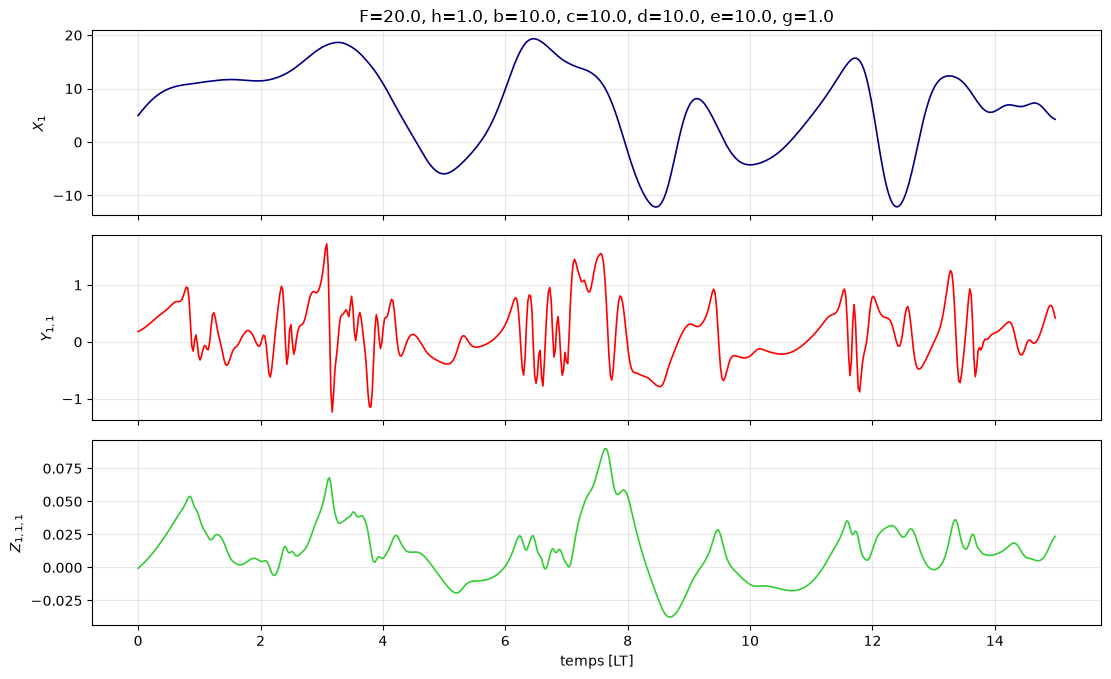

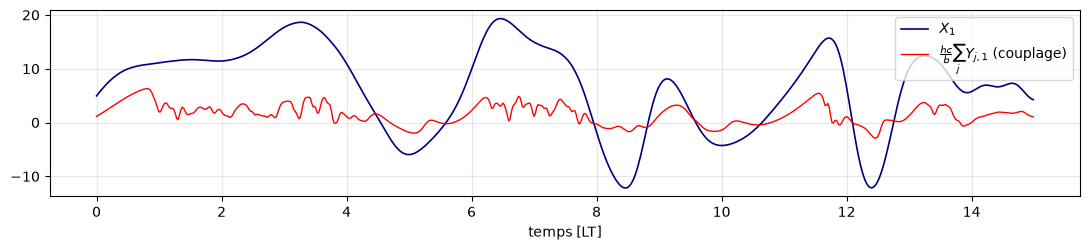

In [4]:
# ------------------------------ series temporelles (cf. Fig. 1 du papier) ------------------------------
tl = t*LAMBDA                                   # axe en temps de Lyapunov
rows = [("$X_1$", Xs[:, 0], "navy")]
if USE_Y: rows.append(("$Y_{1,1}$", Ys[:, 0, 0], "red"))
if use_Z: rows.append(("$Z_{1,1,1}$", Zs[:, 0, 0, 0], "limegreen"))

fig, ax = plt.subplots(len(rows), 1, figsize=(11, 2.3*len(rows)), sharex=True, squeeze=False)
for a, (lab, y, col) in zip(ax[:, 0], rows):
    a.plot(tl, y, color=col, lw=1.2); a.set_ylabel(lab); a.grid(alpha=.3)
ax[-1, 0].set_xlabel("temps [LT]")
ax[0, 0].set_title(f"F={F}, h={h}, b={b}, c={c}, d={d}, e={e}, g={g}")
plt.tight_layout(); plt.show()

# X_1 et sa somme de Y : quelle part de la dynamique de X vient de Y ?
if USE_Y:
    fig, ax = plt.subplots(figsize=(11, 2.6))
    ax.plot(tl, Xs[:, 0], "navy", lw=1.2, label="$X_1$")
    ax.plot(tl, h*c/b*Ys[:, :, 0].sum(1), "red", lw=1, label=r"$\frac{hc}{b}\sum_j Y_{j,1}$ (couplage)")
    ax.set_xlabel("temps [LT]"); ax.legend(loc="upper right"); ax.grid(alpha=.3)
    plt.tight_layout(); plt.show()


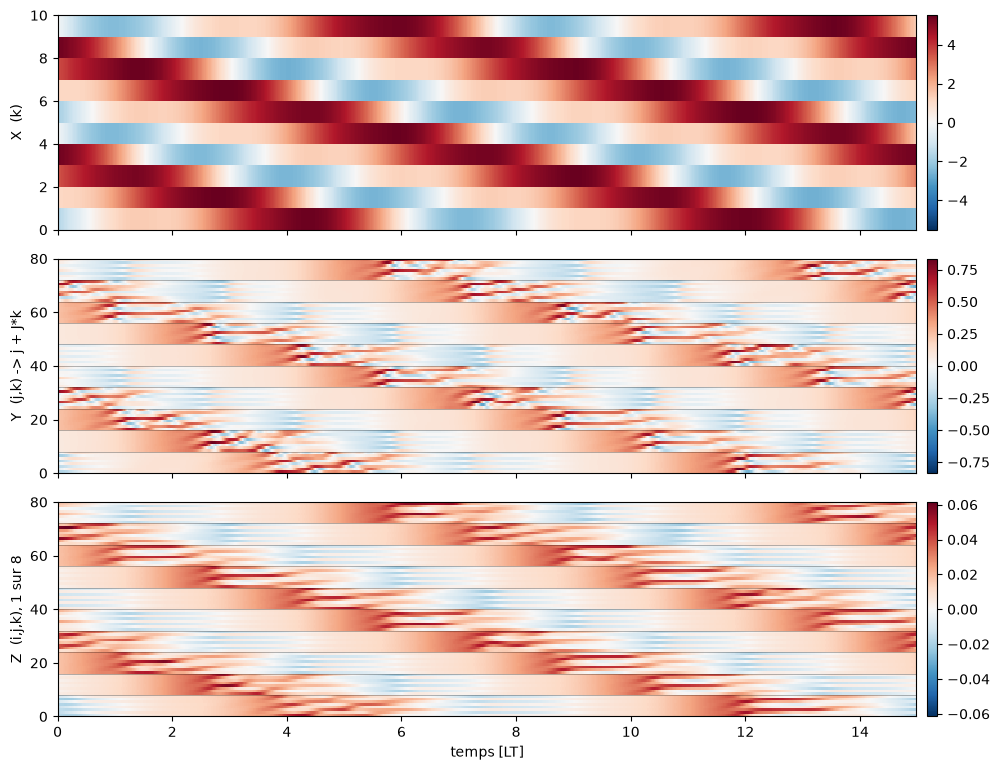

In [9]:
# ------------------------------ vue spatio-temporelle (Hovmoller) ------------------------------
maps = [("X  (k)", Xs.T, K)]
if USE_Y: maps.append(("Y  (j,k) -> j + J*k", Ys.transpose(0, 2, 1).reshape(n_steps, -1).T, K*J))
if use_Z: maps.append(("Z  (i,j,k), 1 sur 8", Zs.transpose(0, 2, 1, 3).reshape(n_steps, -1)[:, ::8].T, K*J*I//8))

fig, ax = plt.subplots(len(maps), 1, figsize=(11, 2.6*len(maps)), sharex=True, squeeze=False)
for a, (lab, M, n) in zip(ax[:, 0], maps):
    v = np.abs(M).max()
    im = a.imshow(M, aspect="auto", origin="lower", cmap="RdBu_r", vmin=-v, vmax=v,
                  extent=[tl[0], tl[-1], 0, n], interpolation="nearest")   # pas de lissage
    if n > K:                                   # traits = frontieres entre secteurs k
        for kk in range(1, K): a.axhline(kk*n/K, color="k", lw=.4, alpha=.5)
    a.set_ylabel(lab); plt.colorbar(im, ax=a, pad=.01)
ax[-1, 0].set_xlabel("temps [LT]")
plt.tight_layout(); plt.show()


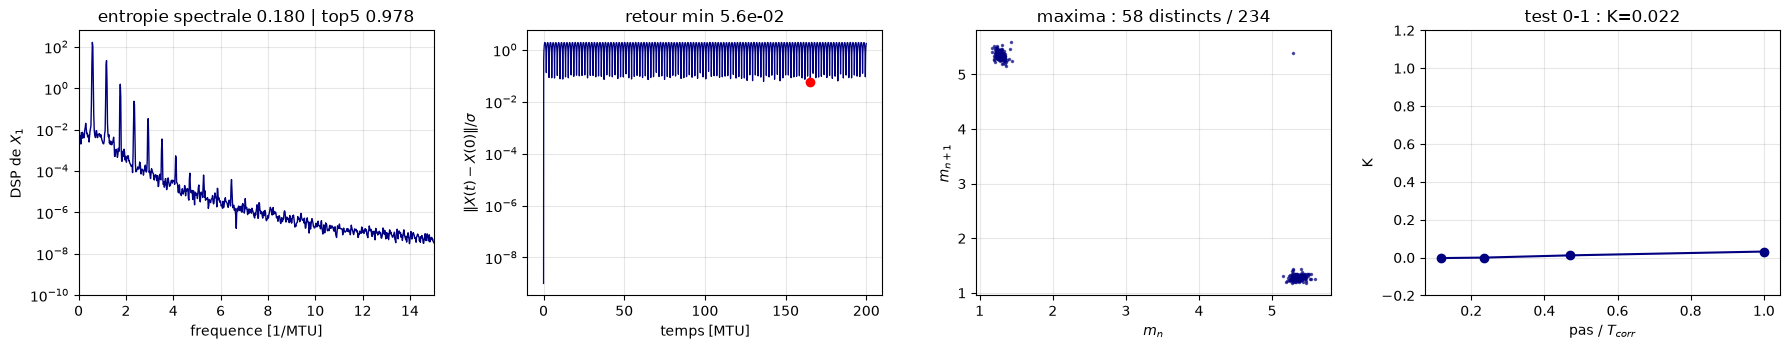

T_corr = 0.340 MTU
  entropie spectrale   : periodique
  puissance top-5      : periodique
  distance de retour   : ?
  maxima distincts     : ?
  test 0-1             : periodique
  -> 3 periodique / 0 aperiodique


In [10]:
T_TEST, SUB, SEED_T = 200.0, 4, 1

def new_state(seed):
    r = np.random.default_rng(seed)
    return (r.integers(-5, 6, K).astype(float),
            r.standard_normal((J, K)) if USE_Y else None,
            0.05*r.standard_normal((J, K, I)) if use_Z else None)

St = new_state(SEED_T)
for _ in range(int(SPIN_UP/dt)): St = rk4(St)
n_t = int(round(T_TEST/dt)); Xt = np.empty((n_t//SUB, K))
for n in range(n_t):
    St = rk4(St)
    if n % SUB == 0: Xt[n//SUB] = St[0]
dt_s = dt*SUB; tt = np.arange(len(Xt))*dt_s; x1 = Xt[:, 0]

from scipy.signal import welch, find_peaks

Xc = Xt - Xt.mean(0); nac = len(Xt)//2
ac = np.array([np.sum(Xc[:len(Xc)-k]*Xc[k:])/np.sum(Xc*Xc) for k in range(nac)])
i_dec = int(np.argmax(np.abs(ac) < .2)) if np.any(np.abs(ac) < .2) else nac-1
T_corr = i_dec*dt_s

f_, P = welch(x1-x1.mean(), fs=1/dt_s, nperseg=min(8192, len(x1)//4))
P, f_ = P[f_ > 0], f_[f_ > 0]
S_ent = -np.sum((P/P.sum())*np.log(P/P.sum()))/np.log(len(P))
top5  = np.sort(P)[::-1][:5].sum()/P.sum()

dist = np.linalg.norm(Xt-Xt[0], axis=1)/np.linalg.norm(Xt.std(0))
i_rec = int(np.argmin(np.where(tt > max(2*T_corr, .5), dist, np.inf))); d_rec = dist[i_rec]

mx = x1[find_peaks(x1)[0]]; n_uniq = len(np.unique(np.round(mx, 2)))

def test_0_1(phi, n_c=60, seed=0):   # sensible au sur-echantillonnage -> on balaie le pas
    r = np.random.default_rng(seed); N = len(phi); ns = np.arange(1, N//10+1); Ks = []
    for cc in r.uniform(np.pi/5, 4*np.pi/5, n_c):
        p = np.cumsum(phi*np.cos(np.arange(N)*cc)); q = np.cumsum(phi*np.sin(np.arange(N)*cc))
        M = np.array([np.mean((p[n:]-p[:-n])**2 + (q[n:]-q[:-n])**2) for n in ns])
        Ks.append(np.corrcoef(ns, M - phi.mean()**2*(1-np.cos(ns*cc))/(1-np.cos(cc)))[0, 1])
    return float(np.median(Ks))

Kv, dv = [], []
for fr in [.1, .25, .5, 1., 2.]:
    st = max(1, int(round(fr*T_corr/dt_s))); phi = x1[::st][:4000]
    if len(phi) > 400: Kv.append(test_0_1(phi)); dv.append(st*dt_s)
Kv, dv = np.array(Kv), np.array(dv)
K01 = float(np.median(Kv[dv >= .25*T_corr])) if np.any(dv >= .25*T_corr) else float(Kv[-1])

fig, ax = plt.subplots(1, 4, figsize=(18, 3.6))
ax[0].semilogy(f_, P, lw=1, color="navy"); ax[0].set_xlim(0, min(f_[-1], 15))
ax[0].set_xlabel("frequence [1/MTU]"); ax[0].set_ylabel("DSP de $X_1$"); ax[0].grid(alpha=.3)
ax[0].set_title(f"entropie spectrale {S_ent:.3f} | top5 {top5:.3f}")
ax[1].semilogy(tt, np.maximum(dist, 1e-9), lw=.9, color="navy")
ax[1].plot(tt[i_rec], max(d_rec, 1e-9), "ro"); ax[1].grid(alpha=.3)
ax[1].set_xlabel("temps [MTU]"); ax[1].set_ylabel(r"$\|X(t)-X(0)\|/\sigma$")
ax[1].set_title(f"retour min {d_rec:.1e}")
ax[2].plot(mx[:-1], mx[1:], ".", ms=3, color="navy", alpha=.6); ax[2].grid(alpha=.3)
ax[2].set_xlabel("$m_n$"); ax[2].set_ylabel("$m_{n+1}$")
ax[2].set_title(f"maxima : {n_uniq} distincts / {len(mx)}")
ax[3].plot(dv/T_corr, Kv, "o-", color="navy"); ax[3].set_ylim(-.2, 1.2); ax[3].grid(alpha=.3)
ax[3].set_xlabel(r"pas / $T_{corr}$"); ax[3].set_ylabel("K"); ax[3].set_title(f"test 0-1 : K={K01:.3f}")
plt.tight_layout(); plt.show()

votes = {"entropie spectrale": S_ent < .25 and "periodique" or (S_ent > .45 and "aperiodique" or "?"),
         "puissance top-5":    top5 > .8   and "periodique" or (top5 < .4   and "aperiodique" or "?"),
         "distance de retour": d_rec < 1e-2 and "periodique" or (d_rec > 1e-1 and "aperiodique" or "?"),
         "maxima distincts":   n_uniq/len(mx) < .1 and "periodique" or (n_uniq/len(mx) > .5 and "aperiodique" or "?"),
         "test 0-1":           K01 < .2   and "periodique" or (K01 > .8   and "aperiodique" or "?")}
print(f"T_corr = {T_corr:.3f} MTU")
for k_, v in votes.items(): print(f"  {k_:<20} : {v}")
print(f"  -> {sum(v=='periodique' for v in votes.values())} periodique / "
      f"{sum(v=='aperiodique' for v in votes.values())} aperiodique")

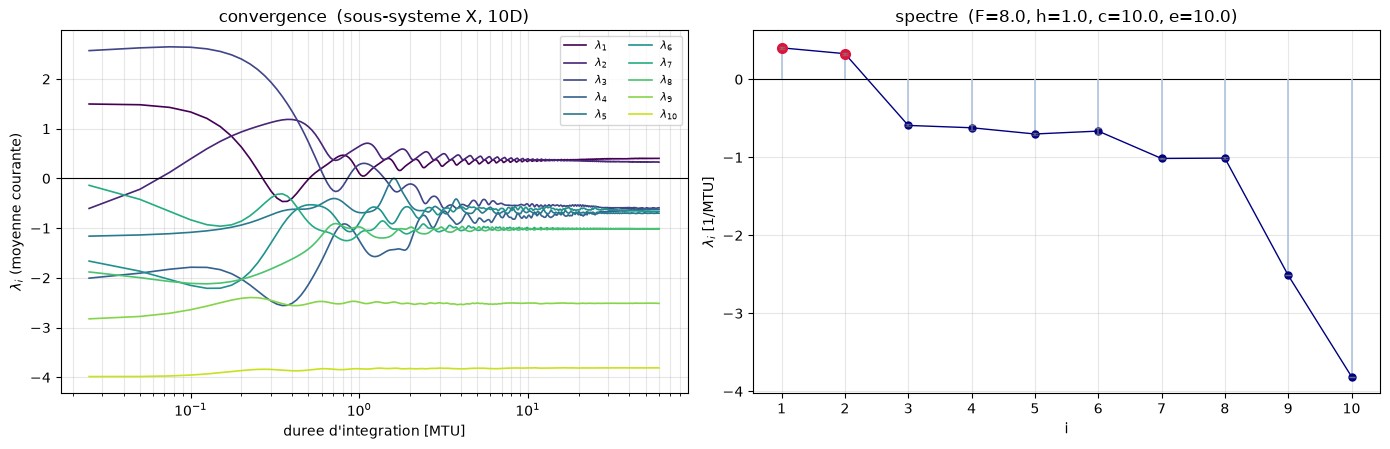

sous-systeme X (10D), 60.0 MTU
  i    lambda_i   1/lambda [MTU]     derive
  1      0.4029           2.4819     0.0131
  2      0.3281           3.0478     0.0136
  3     -0.5917                -     0.0119
  4     -0.6215                -     0.0329
  5     -0.7013                -     0.0091
  6     -0.6643                -     0.0347
  7     -1.0151                -     0.0104
  8     -1.0107                -     0.0105
  9     -2.5125                -     0.0003
 10     -3.8108                -     0.0002

lambda_1 = 0.4029 /MTU  ->  1 LT = 2.4819 MTU = 496 pas   (LAMBDA du notebook : 4.5)
exposants positifs : 2/10 calcules (sur 10)


In [11]:
LYAP_ON  = "X"       # "X", "Y", "Z", "XY", "YZ", "XYZ" : blocs ou vit la perturbation
N_EXP    = 10
T_LYAP   = 60.0
T_TRANS  = 5.0
N_QR     = 5
SEED_L   = 2

_blocks = [("X", (K,)), ("Y", (J, K) if USE_Y else None), ("Z", (J, K, I) if use_Z else None)]
_names  = [nm for nm, sh in _blocks if sh is not None and nm in LYAP_ON]
n_sub   = sum(int(np.prod(sh)) for nm, sh in _blocks if sh is not None and nm in _names)
N_EXP   = min(N_EXP, n_sub)

def tangent(X, Y, Z, dX, dY, dZ):
    tX = (np.roll(dX, 1, 0)*(np.roll(X, -1) - np.roll(X, 2))[:, None]
          + np.roll(X, 1)[:, None]*(np.roll(dX, -1, 0) - np.roll(dX, 2, 0)) - dX)
    tY = tZ = None
    if Y is not None:
        tX = tX - h*c/b*dY.sum(0)
        tY = (-c*b*(np.roll(dY, -1, 0)*(np.roll(Y, -2, 0) - np.roll(Y, 1, 0))[..., None]
                    + np.roll(Y, -1, 0)[..., None]*(np.roll(dY, -2, 0) - np.roll(dY, 1, 0)))
              - c*dY + h*c/b*dX[None, :, :])
        if Z is not None:
            tY = tY - h*e/d*dZ.sum(2)
            tZ = (e*d*(np.roll(dZ, 1, 2)*(np.roll(Z, -1, 2) - np.roll(Z, 2, 2))[..., None]
                       + np.roll(Z, 1, 2)[..., None]*(np.roll(dZ, -1, 2) - np.roll(dZ, 2, 2)))
                  - g*e*dZ + h*e/d*dY[:, :, None, :])
    return tX, tY, tZ

def rk4_joint(S, P):
    a1 = rhs(*S);          b1 = tangent(*S, *P)
    S2 = add(S, a1, dt/2); P2 = add(P, b1, dt/2); a2 = rhs(*S2); b2 = tangent(*S2, *P2)
    S3 = add(S, a2, dt/2); P3 = add(P, b2, dt/2); a3 = rhs(*S3); b3 = tangent(*S3, *P3)
    S4 = add(S, a3, dt);   P4 = add(P, b3, dt);   a4 = rhs(*S4); b4 = tangent(*S4, *P4)
    return (tuple(None if s is None else s + dt/6*(u+2*v+2*w+z) for s,u,v,w,z in zip(S,a1,a2,a3,a4)),
            tuple(None if p is None else p + dt/6*(u+2*v+2*w+z) for p,u,v,w,z in zip(P,b1,b2,b3,b4)))

def project(P):          # remet a zero les blocs hors du sous-systeme choisi
    return tuple(p if (p is None or nm in _names) else np.zeros_like(p)
                 for nm, p in zip(("X", "Y", "Z"), P))

def pack(P):
    return np.concatenate([P[i].reshape(-1, N_EXP)
                           for i, (nm, _) in enumerate(_blocks) if nm in _names], 0)

def unpack(M):
    out, o = [None, None, None], 0
    for i, (nm, sh) in enumerate(_blocks):
        if sh is None: continue
        if nm in _names:
            nn = int(np.prod(sh)); out[i] = M[o:o+nn].reshape(*sh, N_EXP); o += nn
        else:
            out[i] = np.zeros((*sh, N_EXP))
    return tuple(out)

Sl = new_state(SEED_L)
for _ in range(int(SPIN_UP/dt)): Sl = rk4(Sl)
Q, _ = np.linalg.qr(np.random.default_rng(SEED_L).standard_normal((n_sub, N_EXP)))
P = unpack(Q)

for n in range(int(T_TRANS/dt)):                      # transitoire, on n'accumule pas
    Sl, P = rk4_joint(Sl, P); P = project(P)
    if (n+1) % N_QR == 0:
        Q, _ = np.linalg.qr(pack(P)); P = unpack(Q)

n_run = int(T_LYAP/dt); n_rec = n_run//N_QR
lam_c = np.zeros((n_rec, N_EXP)); t_c = np.zeros(n_rec); acc = np.zeros(N_EXP); mq = 0
for n in range(n_run):
    Sl, P = rk4_joint(Sl, P); P = project(P)
    if (n+1) % N_QR == 0:
        Q, R = np.linalg.qr(pack(P)); acc += np.log(np.abs(np.diag(R))); P = unpack(Q)
        t_c[mq] = (n+1)*dt; lam_c[mq] = acc/t_c[mq]; mq += 1
    if not np.isfinite(Sl[0]).all(): raise FloatingPointError("divergence : baisse dt")
lam = lam_c[-1]; drift = np.abs(lam - lam_c[n_rec//2])

cmap = plt.cm.viridis(np.linspace(0, .92, N_EXP))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
for i in range(N_EXP):
    ax[0].plot(t_c, lam_c[:, i], color=cmap[i], lw=1.2, label=f"$\\lambda_{{{i+1}}}$")
ax[0].axhline(0, color="k", lw=.8); ax[0].set_xscale("log")
ax[0].set_xlabel("duree d'integration [MTU]"); ax[0].set_ylabel(r"$\lambda_i$ (moyenne courante)")
ax[0].set_title(f"convergence  (sous-systeme {LYAP_ON}, {n_sub}D)")
ax[0].grid(alpha=.3, which="both"); ax[0].legend(ncol=2, fontsize=8)

idx = np.arange(1, N_EXP+1)
ax[1].axhline(0, color="k", lw=.8)
ax[1].vlines(idx, 0, lam, color="lightsteelblue", lw=1.2)
ax[1].plot(idx, lam, "o-", color="navy", ms=5, lw=1)
if (lam > 0).any(): ax[1].plot(idx[lam > 0], lam[lam > 0], "o", color="crimson", ms=7)
ax[1].errorbar(idx, lam, yerr=drift, fmt="none", ecolor="gray", alpha=.6, capsize=2)
ax[1].set_xticks(idx); ax[1].set_xlabel("i"); ax[1].set_ylabel(r"$\lambda_i$ [1/MTU]")
ax[1].set_title(f"spectre  (F={F}, h={h}, c={c}, e={e})"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

print(f"sous-systeme {LYAP_ON} ({n_sub}D), {T_LYAP} MTU")
print(f"{'i':>3} {'lambda_i':>11} {'1/lambda [MTU]':>16} {'derive':>10}")
for i in range(N_EXP):
    print(f"{i+1:>3} {lam[i]:>11.4f} {(f'{1/lam[i]:.4f}' if lam[i] > 1e-6 else '-'):>16} {drift[i]:>10.4f}")
if lam[0] > 0:
    print(f"\nlambda_1 = {lam[0]:.4f} /MTU  ->  1 LT = {1/lam[0]:.4f} MTU = {1/lam[0]/dt:.0f} pas"
          f"   (LAMBDA du notebook : {LAMBDA})")
else:
    print(f"\nlambda_1 = {lam[0]:.4f} <= 0  ->  pas de chaos dans ce sous-systeme")
print(f"exposants positifs : {int((lam>0).sum())}/{N_EXP} calcules (sur {n_sub})")
if LYAP_ON == "X" and not USE_Y and N_EXP == K:
    print(f"controle trace : {lam.sum():.4f}  (theorie {-float(K)})")